In [44]:
import numpy as np
from math import exp, log
import random
import matplotlib.pyplot as plt

# Framework definition

In [45]:
# Copy and pasted from https://github.com/rasmusbergpalm/nanograd/blob/3a1bf9e9e724da813bfccf91a6f309abdade9f39/nanograd.py



class Var:
    """
    A variable which holds a float and enables gradient computations.
    """

    def __init__(self, val: float, grad_fn=lambda: []):
        assert type(val) == float
        self.v = val
        self.grad_fn = grad_fn
        self.grad = 0.0

    def backprop(self, bp):
        self.grad += bp
        for input, grad in self.grad_fn():
            input.backprop(grad * bp)

    def backward(self):
        self.backprop(1.0)

    def relu(self):
        return Var(self.v if self.v > 0.0 else 0.0, lambda: [(self, 1.0 if self.v > 0.0 else 0.0)])

    def identity(self):
        return Var(self.v, lambda: [(self, 1.0)])

    def tanh(self):
        t = (exp(self.v) - exp(-self.v)) / (exp(self.v) + exp(-self.v))
        return Var(t, lambda: [(self, 1.0 - t ** 2)])

    def sigmoid(self):
        s = 1.0 / (1.0 + exp(-self.v))
        return Var(s, lambda: [(self, s * (1.0 - s))])
    
    def __add__(self: 'Var', other: 'Var') -> 'Var':
        return Var(self.v + other.v, lambda: [(self, 1.0), (other, 1.0)])

    def __mul__(self: 'Var', other: 'Var') -> 'Var':
        return Var(self.v * other.v, lambda: [(self, other.v), (other, self.v)])

    def __pow__(self, power):
        assert type(power) in {float, int}, "power must be float or int"
        return Var(self.v ** power, lambda: [(self, power * self.v ** (power - 1))])

    def __neg__(self: 'Var') -> 'Var':
        return Var(-1.0) * self

    def __sub__(self: 'Var', other: 'Var') -> 'Var':
        return self + (-other)

    def __truediv__(self: 'Var', other: 'Var') -> 'Var':
        return self * other ** -1

    def __repr__(self):
        return "Var(v=%.4f, grad=%.4f)" % (self.v, self.grad)

    def relu(self):
        return Var(self.v if self.v > 0.0 else 0.0, lambda: [(self, 1.0 if self.v > 0.0 else 0.0)])

In [46]:
class Initializer:

  def init_weights(self, n_in, n_out):
    raise NotImplementedError

  def init_bias(self, n_out):
    raise NotImplementedError

In [47]:
class NormalInitializer(Initializer):

  def __init__(self, mean=0, std=0.1):
    self.mean = mean
    self.std = std

  def init_weights(self, n_in, n_out):
    return [[Var(random.gauss(self.mean, self.std)) for _ in range(n_out)] for _ in range(n_in)]

  def init_bias(self, n_out):
    return [Var(0.0) for _ in range(n_out)]

class ConstantInitializer(Initializer):

  def __init__(self, weight=1.0, bias=0.0):
    self.weight = weight
    self.bias = bias

  def init_weights(self, n_in, n_out):
    return [[Var(self.weight) for _ in range(n_out)] for _ in range(n_in)]

  def init_bias(self, n_out):
    return [Var(self.bias) for _ in range(n_out)]

In [48]:
def forward(input, network):

    def forward_single(x, network):
        for layer in network:
            x = layer.forward(x)
        return x

    output = [
        forward_single(input[n], network)
        for n in range(len(input))
    ]

    return output

class DenseLayer:
    def __init__(
        self,
        n_in: int,
        n_out: int,
        act_fn,
        initializer=NormalInitializer()
    ):
        self.weights = initializer.init_weights(n_in, n_out)
        self.bias = initializer.init_bias(n_out)
        self.act_fn = act_fn

    def __repr__(self):
        return (
            'Weights: ' + repr(self.weights)
            + ' Biases: ' + repr(self.bias)
        )

    def parameters(self):
        params = []

        for r in self.weights:
            params += r

        return params + self.bias

    def forward(self, single_input):
        assert len(self.weights) == len(single_input)

        weights = self.weights
        out = []

        for j in range(len(weights[0])):

            # Start with the bias of neuron j
            node = self.bias[j]

            # Weighted sum of inputs
            for i in range(len(single_input)):
                node += single_input[i] * weights[i][j]

            # Activation
            node = self.act_fn(node)

            out.append(node)

        return out

In [49]:
def parameters(network):
    params = []

    for layer in range(len(network)):
        params += network[layer].parameters()

    return params


def update_parameters(params, learning_rate=0.01):
    for p in params:
        p.v -= learning_rate * p.grad


def zero_gradients(params):
    for p in params:
        p.grad = 0.0

In [50]:
def squared_loss(t, y):
  
  # add check that sizes agree
  
  def squared_loss_single(t, y):
    Loss = Var(0.0)
    for i in range(len(t)): # sum over outputs
      Loss += (t[i]-y[i]) ** 2
    return Loss

  Loss = Var(0.0)
  for n in range(len(t)): # sum over training data
    Loss += squared_loss_single(t[n],y[n])
  return Loss

# Data

In [51]:
n_samples = 300
noise = 0.1

X = np.random.uniform(-3, 3, size=(n_samples, 2))
np.random.shuffle(X)

y1 = np.sin(X[:, 0]) + X[:, 1]
y2 = np.cos(X[:, 1]) - X[:, 0]
y3 = X[:, 0] * X[:, 1]

Y = np.vstack((y1, y2, y3)).T + np.random.normal(0, noise, size=(n_samples, 3))

data_set = np.hstack((X, Y))

train, validation, test = np.split(data_set, [int(0.35*n_samples), int(0.7*n_samples)], axis=0)

train_mu = np.mean(train, axis=0)
train_sigma = np.std(train, axis=0)

train = (train - train_mu) / train_sigma
validation = (validation - train_mu) / train_sigma
test = (test - train_mu) / train_sigma

x_train, x_validation, x_test = train[:, :2], validation[:, :2], test[:, :2]
y_train, y_validation, y_test = train[:, 2:], validation[:, 2:], test[:, 2:]

def nparray_to_Var(x):
  if x.ndim==1:
    y = [[Var(float(x[i]))] for i in range(x.shape[0])] # always work with list of list
  else:
    y = [[Var(float(x[i,j])) for j in range(x.shape[1])] for i in range(x.shape[0])]
  return y

x_train = nparray_to_Var(x_train)
y_train = nparray_to_Var(y_train)
x_validation = nparray_to_Var(x_validation)
y_validation = nparray_to_Var(y_validation)
x_test = nparray_to_Var(x_test)
y_test = nparray_to_Var(y_test)

# Model 1

Consider the fully connected neural network shown below, where x ∈ R^2 is the input and y ∈ R^3 is the output

It's a fully connected NN, with 4 hidden layers, assume each neuron has a bias term. 

In [52]:
# We define the model with the structure and some activation functions
NN = [
    DenseLayer(2, 4, lambda x: x.relu()),
    DenseLayer(4, 3, lambda x: x.identity())
]
len(parameters(NN))

for layer in NN:
    print(len(layer.parameters()))

12
15


In [53]:
EPOCHS = 200
LEARN_R = 2e-3

train_loss = []
val_loss = []

for e in range(EPOCHS):

    # -------------------------
    # Forward pass
    # -------------------------
    y_pred = forward(x_train, NN)

    Loss = squared_loss(
        y_train,
        y_pred
    )

    # -------------------------
    # Backward pass
    # -------------------------
    Loss.backward()

    # -------------------------
    # Gradient descent
    # -------------------------
    update_parameters(
        parameters(NN),
        LEARN_R
    )

    # VERY IMPORTANT:
    zero_gradients(parameters(NN))

    # -------------------------
    # Record training loss
    # -------------------------
    train_loss.append(Loss.v)

    # -------------------------
    # Validation
    # -------------------------
    y_val_pred = forward(
        x_validation,
        NN
    )

    Loss_validation = squared_loss(
        y_validation,
        y_val_pred
    )

    val_loss.append(
        Loss_validation.v
    )

    if e % 10 == 0:
        print(
            f"{e:4d} "
            f"Train loss: {train_loss[-1]:8.3f} "
            f"Validation loss: {val_loss[-1]:8.3f}"
        )

   0 Train loss:  319.974 Validation loss:  307.700
  10 Train loss:  195.361 Validation loss:  185.882
  20 Train loss:  119.155 Validation loss:  121.063
  30 Train loss:   85.416 Validation loss:   85.309
  40 Train loss:   52.387 Validation loss:   49.671
  50 Train loss:   37.899 Validation loss:   35.454
  60 Train loss:   67.703 Validation loss:   79.904
  70 Train loss:   26.323 Validation loss:   23.067
  80 Train loss:   17.668 Validation loss:   17.238
  90 Train loss:   15.228 Validation loss:   15.284
 100 Train loss:   13.517 Validation loss:   13.726
 110 Train loss:   11.781 Validation loss:   12.114
 120 Train loss:   10.769 Validation loss:   11.124
 130 Train loss:   10.353 Validation loss:   10.659
 140 Train loss:   10.138 Validation loss:   10.424
 150 Train loss:    9.994 Validation loss:   10.283
 160 Train loss:    9.897 Validation loss:   10.209
 170 Train loss:    9.829 Validation loss:   10.190
 180 Train loss:    9.781 Validation loss:   10.177
 190 Train l

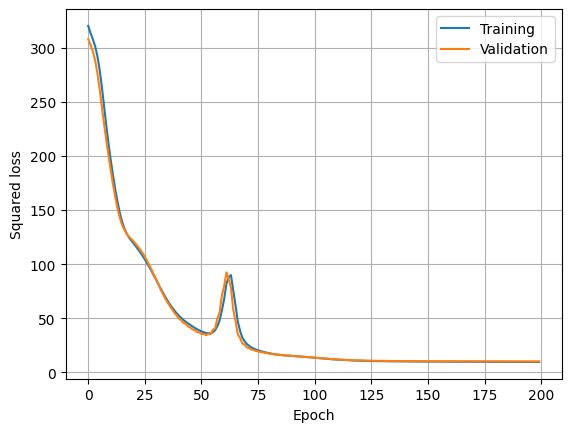

In [54]:
plt.plot(
    range(len(train_loss)),
    train_loss,
    label="Training"
)

plt.plot(
    range(len(val_loss)),
    val_loss,
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Squared loss")
plt.legend()
plt.grid()

plt.show()

In [57]:
output_test = forward(
    x_test,
    NN
)

Loss_test = squared_loss(
    y_test,
    output_test
)

print(
    f"Test loss: {Loss_test.v:.3f}"
)



Test loss: 10.372
